# Telco Customer Churn Prediction

Predicting which telecom customers are likely to leave (churn) using classification models.

**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 columns). Place the CSV in `data/` (see the project README).

**Workflow:** data cleaning → exploratory analysis → baseline → Logistic Regression → Random Forest → comparison.

## 1. Data loading and cleaning

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

In [ ]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.shape

(7043, 21)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [ ]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [ ]:
df.duplicated().sum()

0

In [ ]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [ ]:
df["TotalCharges"].head(10)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: object

In [ ]:
pd.to_numeric(df["TotalCharges"], errors="coerce").isnull().sum()

11

In [ ]:
df[pd.to_numeric(df["TotalCharges"], errors="coerce").isnull()]["TotalCharges"]

488      
753      
936      
1082     
1340     
3331     
3826     
4380     
5218     
6670     
6754     
Name: TotalCharges, dtype: object

In [ ]:
df["TotalCharges"].isnull().sum()

0

In [ ]:
df["TotalCharges"].dtype


dtype('O')

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [ ]:
df["TotalCharges"].dtype


dtype('float64')

In [ ]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [ ]:
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

In [ ]:
df["TotalCharges"].isnull().sum()

0

## 2. Exploratory data analysis

### Numerical features

In [ ]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2281.916928
std,24.559481,30.090047,2265.270398
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,402.225000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


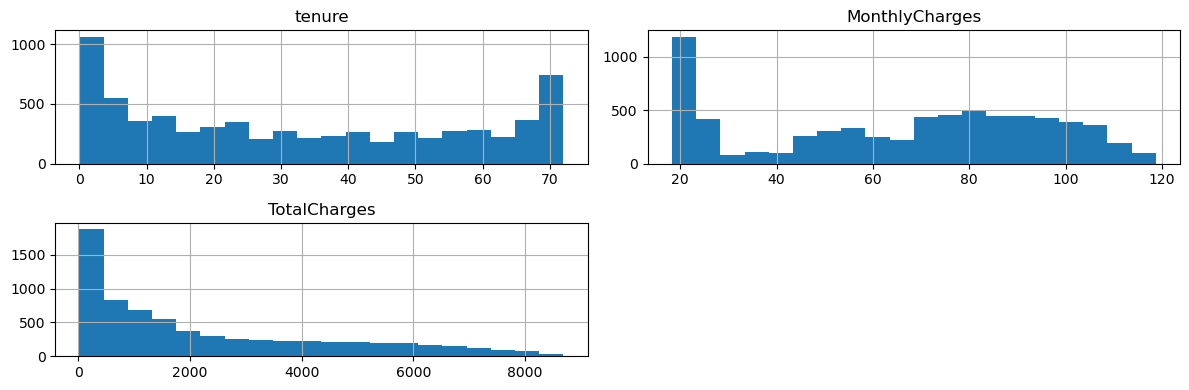

In [ ]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].hist(
    figsize=(12, 4),
    bins=20
)

plt.tight_layout()
plt.show()

### Categorical features and churn rate

In [ ]:
df[[
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]].apply(lambda col: col.value_counts())

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod
Bank transfer (automatic),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1544.0
Credit card (automatic),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1522.0
DSL,NaN,NaN,NaN,NaN,NaN,2421.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Electronic check,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2365.0
Female,3488.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fiber optic,NaN,NaN,NaN,NaN,NaN,3096.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mailed check,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1612.0
Male,3555.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Month-to-month,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3875.0,NaN,NaN
No,NaN,3641.0,4933.0,682.0,3390.0,1526.0,3498.0,3088.0,3095.0,3473.0,2810.0,2785.0,NaN,2872.0,NaN


In [ ]:
pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [ ]:
pd.crosstab(df["InternetService"], df["Churn"], normalize="index") * 100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


## 3. Modelling

### 3.1 Train/test split, encoding and scaling

In [ ]:
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

print(X.shape)
print(y.shape)

(7043, 19)
(7043,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape)
print(X_test.shape)

(5634, 19)
(1409, 19)


In [ ]:
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(X_train.shape)
print(X_test.shape)

(5634, 30)
(1409, 30)


### 3.2 Logistic Regression (default settings)

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8069552874378992


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [ ]:
print(confusion_matrix(y_test, y_pred))

[[925 110]
 [162 212]]


### 3.3 Baseline: always predict "No"

In [ ]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_scaled, y_train)

DummyClassifier(strategy='most_frequent')

Evaluating the baseline:

In [ ]:
y_pred_base = baseline.predict(X_test_scaled)

print(classification_report(y_test, y_pred_base, zero_division=0))

              precision    recall  f1-score   support

          No       0.73      1.00      0.85      1035
         Yes       0.00      0.00      0.00       374

    accuracy                           0.73      1409
   macro avg       0.37      0.50      0.42      1409
weighted avg       0.54      0.73      0.62      1409



**Baseline conclusion.** A classifier that always predicts "No" (the customer stays) reaches 73 % accuracy simply because 73 % of customers stay. But its recall on churners is 0 %: it detects none of them.

Accuracy alone is therefore not a good metric for this project. The goal is to detect customers who are about to leave, so I focus on the **recall of the "Yes" class** (and F1). My models need to beat this baseline on that metric.

### 3.4 Logistic Regression with balanced class weights

In [ ]:
model2 = LogisticRegression(max_iter=1000, class_weight="balanced")
model2.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [ ]:
y_pred2 = model2.predict(X_test_scaled)

print(classification_report(y_test, y_pred2))

              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



**Balanced logistic regression conclusion.** With `class_weight="balanced"`, the recall of the "Yes" class rises from 0 % (baseline) to 78 %. Precision is 51 %: the model raises false alarms, but it catches the large majority of customers who leave. Accuracy (74 %) is close to the baseline, which confirms that it is not the right metric here.

### 3.5 Random Forest

In [ ]:
rf = RandomForestClassifier(random_state=42, class_weight="balanced")
rf.fit(X_train_scaled, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [ ]:
y_pred_rf = rf.predict(X_test_scaled)

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

          No       0.83      0.89      0.86      1035
         Yes       0.63      0.50      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



## 4. Model comparison

In [ ]:
models = {
    "DummyClassifier": baseline,
    "Logistic Regression": model2,
    "Random Forest": rf
}

for name, clf in models.items():
    y_pred = clf.predict(X_test_scaled)

    print(name)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, pos_label="Yes", zero_division=0))
    print("Recall:", recall_score(y_test, y_pred, pos_label="Yes", zero_division=0))
    print("F1-score:", f1_score(y_test, y_pred, pos_label="Yes", zero_division=0))
    print("--------------------")

DummyClassifier
Accuracy: 0.7345635202271115
Precision: 0.0
Recall: 0.0
F1-score: 0.0
--------------------
Logistic Regression
Accuracy: 0.7388218594748048
Precision: 0.5051903114186851
Recall: 0.7807486631016043
F1-score: 0.6134453781512605
--------------------
Random Forest
Accuracy: 0.7885024840312278
Precision: 0.6283783783783784
Recall: 0.49732620320855614


F1-score: 0.5552238805970149
--------------------


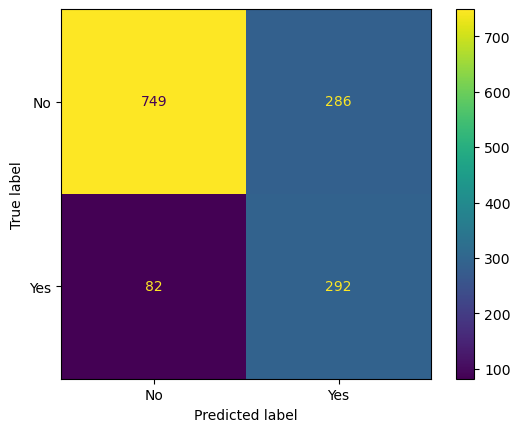

In [ ]:
y_pred_model2 = model2.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred_model2, labels=["No", "Yes"])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot()
plt.show()

## 5. Conclusion

The objective of this project was to predict customer churn with machine-learning classification models.

After cleaning and preprocessing the data, three models were evaluated: a Dummy Classifier (baseline), Logistic Regression (balanced class weights) and Random Forest (balanced class weights).

Logistic Regression achieved the best recall for churn prediction (**78 %**) with an F1-score of **0.61**. This means it is the best at identifying customers likely to leave. Random Forest achieved a higher accuracy (**78.9 %**), but its recall on churners was much lower (**50 %**).

Logistic Regression was therefore selected as the preferred model, because detecting customers at risk of leaving is the key objective for customer retention.

**Possible improvements:** hyperparameter tuning, cross-validation, ROC-AUC analysis, decision-threshold optimisation, and interpretation of the model coefficients.